In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter

JOINT15 = 'JOINT2015.graphml'
LCC15 = 'LCC2015.graphml'
FSNC15 = 'FSNC2015.graphml'

JOINT19 = 'JOINT2019.graphml'
LCC19 = 'LCC2019.graphml'
FSNC19 = 'FSNC2019.graphml'

# Edit filename to print properties of different graph
filename = JOINT15
G = nx.read_graphml(filename)

# Print basic properties
print(filename, "has:") 
print(len(list(G.nodes())) , "nodes.")
print(len(list(G.edges())) , "edges.")
print(nx.density(G), "density.")
print(nx.degree_assortativity_coefficient(G), "assortativity coeff.")
print(sum(dict(G.degree()).values()) / G.number_of_nodes(), "avg degree. not weighted")
print(sum(dict(G.degree(weight = 'weight')).values()) / G.number_of_nodes(), "avg degree. weighted")
print(nx.average_clustering(G), "clustering coefficient")

# Compute the average shortest path length on the largest strongly connected component
LCC = max(nx.strongly_connected_components(G), key=len)
print("largest strongest connected component:", len(LCC), "nodes")
Gcc = G.subgraph(LCC).copy()
avg_path_len = nx.average_shortest_path_length(Gcc)
print("avg shortest path length (strong component):", avg_path_len)

# Betweenness-centrality concentration
betweenness = nx.betweenness_centrality(G, weight='weight')
sorted_bet = sorted(betweenness.items(), key=lambda x: x[1], reverse=True)
total_bet = sum(betweenness.values())
concentration_dict = {}

for N in [1, 5, 10]:
    top_sum = sum(val for node, val in sorted_bet[:N])
    concentration_dict[N] = (top_sum / total_bet) * 100

print("betweenness centrality concentration:", concentration_dict)


test.graphml has:
81 nodes.
324 edges.
0.05 density.
-0.07818772554652374 assortativity coeff.
8.0 avg degree. not weighted
8.518518518518519 avg degree. weighted
0.08321308725002845 clustering coefficient
largest strongest connected component: 63 nodes
avg shortest path length (strong component): 3.2457757296466974
betweenness centrality concentration: {1: 10.262758870190307, 5: 28.314718349329127, 10: 44.32553630318178}


In [ ]:
print("for", filename)
# Weighted out-degree (sum of edge weights)
weighted_out_deg = G.out_degree(weight='weight')  # returns (node, weighted out-degree) pairs
top_out_deg = sorted(weighted_out_deg, key=lambda x: x[1], reverse=True)

# Unweighted out-degree:
unweighted_out_deg = G.out_degree()
top_out_deg_unweighted = sorted(unweighted_out_deg, key=lambda x: x[1], reverse=True)

# Print
N = 40
print(f"Top {N} nodes by weighted out-degree:")
for node, deg in top_out_deg[:N]:
    print(node, deg)

print(f"\ntop {N} nodes by unweighted out-degree:")
for node, deg in top_out_deg_unweighted[:N]:
    print(node, deg)

# Weighted in-degree (sum of edge weights)
weighted_in_deg = G.in_degree(weight='weight')  # returns (node, weighted in-degree) pairs
top_in_deg = sorted(weighted_in_deg, key=lambda x: x[1], reverse=True)

# Unweighted in-degree:
unweighted_in_deg = G.in_degree()
top_in_deg_unweighted = sorted(unweighted_in_deg, key=lambda x: x[1], reverse=True)

# Print
print(f"Top {N} nodes by weighted in-degree:")
for node, deg in top_in_deg[:N]:
    print(node, deg)

print(f"\ntop {N} nodes by unweighted in-degree:")
for node, deg in top_in_deg_unweighted[:N]:
    print(node, deg)

In [ ]:
# Compare 2 changes between networks
# Put older network in filename1

filename1 = LCC15
filename2 = LCC19
G1 = nx.read_graphml(filename1)
G2 = nx.read_graphml(filename2)

print("from", filename1, "to", filename2, "there are:")
remaining_nodes = set(G1.nodes).intersection(G2.nodes)
remaining_edges = set(G1.edges).intersection(G2.edges)

new_nodes = set(G2.nodes).difference(set(G1.nodes))
new_edges = set(G2.edges).difference(set(G1.edges))

print(len(remaining_nodes) / len(list(G1.nodes)) * 100, "% remaining nodes")
print(len(remaining_edges) / len(list(G1.edges)) * 100, "% remaining edges")
print(len(new_nodes), "new nodes")
print(len(new_edges), "new edges")


from LCC2015.graphml to LCC2019.graphml there are:
92.64705882352942 % remaining nodes.
75.7055456877837 % remaining edges.
43 new nodes
2917 new edges


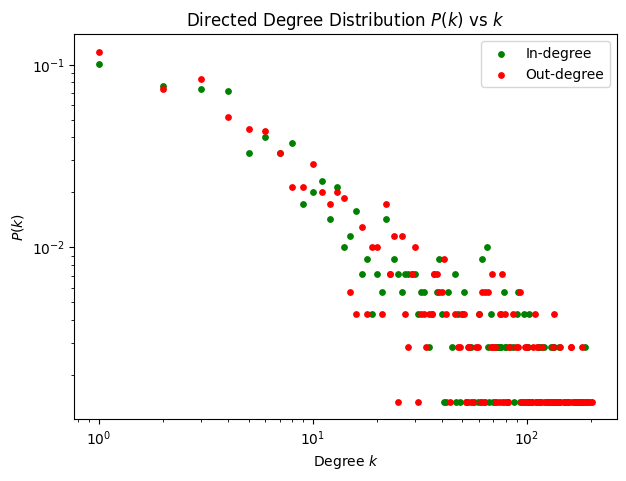

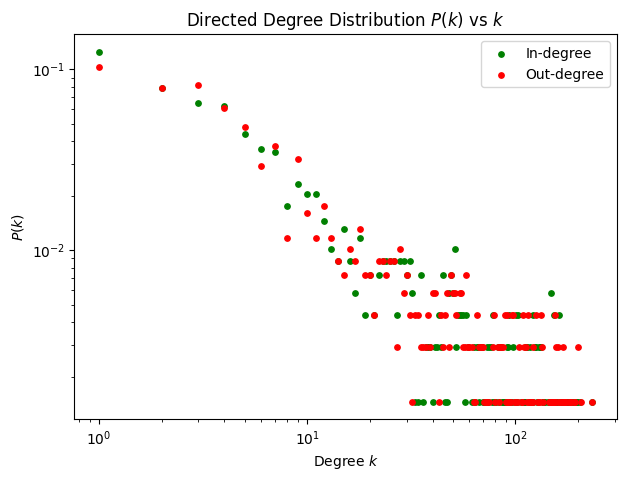

In [29]:
# Plot degree distribution
filename = JOINT15
G = nx.read_graphml(filename)

# In-degree distribution
in_degrees = [d for _, d in G.in_degree()]
in_counts = Counter(in_degrees)
in_k = np.array(list(in_counts.keys()))
in_pk = np.array(list(in_counts.values())) / G.number_of_nodes()

# Out-degree distribution
out_degrees = [d for _, d in G.out_degree()]
out_counts = Counter(out_degrees)
out_k = np.array(list(out_counts.keys()))
out_pk = np.array(list(out_counts.values())) / G.number_of_nodes()

plt.figure(figsize=(7,5))

plt.scatter(in_k, in_pk, c='g', s=15, label="In-degree", )
plt.scatter(out_k, out_pk, c='r', s=15, label="Out-degree")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Degree $k$")
plt.ylabel("$P(k)$")
plt.title("Directed Degree Distribution $P(k)$ vs $k$")
plt.legend()
plt.show()

# Plot degree distribution
filename = JOINT19
G = nx.read_graphml(filename)

# In-degree distribution
in_degrees = [d for _, d in G.in_degree()]
in_counts = Counter(in_degrees)
in_k = np.array(list(in_counts.keys()))
in_pk = np.array(list(in_counts.values())) / G.number_of_nodes()

# Out-degree distribution
out_degrees = [d for _, d in G.out_degree()]
out_counts = Counter(out_degrees)
out_k = np.array(list(out_counts.keys()))
out_pk = np.array(list(out_counts.values())) / G.number_of_nodes()

plt.figure(figsize=(7,5))

plt.scatter(in_k, in_pk, c='g', s=15, label="In-degree", )
plt.scatter(out_k, out_pk, c='r', s=15, label="Out-degree")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Degree $k$")
plt.ylabel("$P(k)$")
plt.title("Directed Degree Distribution $P(k)$ vs $k$")
plt.legend()
plt.show()



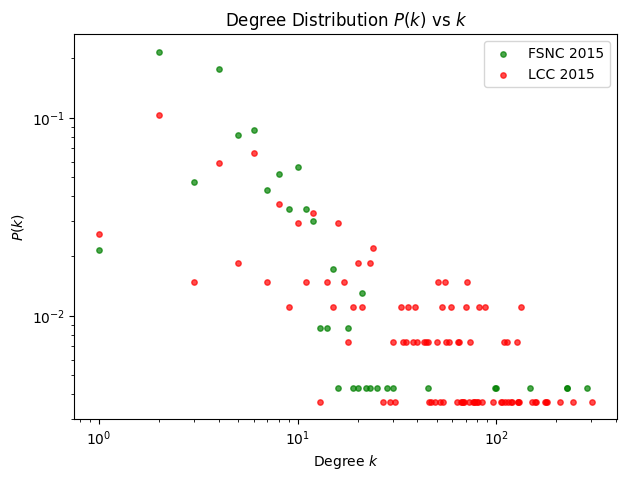

In [22]:
# Plot degree distribution of 2 networks against one another 
filename1 = FSNC15
filename2 = LCC15
G1 = nx.read_graphml(filename1)
G2 = nx.read_graphml(filename2)

degrees = [d for _, d in G1.degree()]
counts = Counter(degrees)
k1 = np.array(list(counts.keys()))
pk1 = np.array(list(counts.values())) / G1.number_of_nodes()

degrees = [d for _, d in G2.degree()]
counts = Counter(degrees)
k2 = np.array(list(counts.keys()))
pk2 = np.array(list(counts.values())) / G2.number_of_nodes()


plt.figure(figsize=(7,5))

plt.scatter(k1, pk1, s=15, c='g', alpha=0.7, label='FSNC 2015')
plt.scatter(k2, pk2, s=15, c='r', alpha=0.7, label='LCC 2015')

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Degree $k$")
plt.ylabel("$P(k)$")
plt.title("Degree Distribution $P(k)$ vs $k$")
plt.legend()
plt.show()

In [ ]:

# ----- Degree sequences -----
in_degree_sequence = sorted([d for _, d in G.in_degree()], reverse=True)
out_degree_sequence = sorted([d for _, d in G.out_degree()], reverse=True)

plt.figure(figsize=(6,5))

# Rank plot
plt.plot(in_degree_sequence, label="In-degree")
plt.plot(out_degree_sequence, label="Out-degree")

plt.title("Directed Degree Rank Plot of "+ filename)
plt.xlabel("Rank")
plt.ylabel("Degree")
plt.legend()
plt.tight_layout()
plt.show()


# ----- Degree sequences -----
in_degree_sequence = sorted([d for _, d in G.in_degree(weight='weight')], reverse=True)
out_degree_sequence = sorted([d for _, d in G.out_degree(weight='weight')], reverse=True)

plt.figure(figsize=(6,5))

# Rank plot
plt.plot(in_degree_sequence, label="In-degree")
plt.plot(out_degree_sequence, label="Out-degree")

plt.title("Weighted Directed Degree Rank Plot of "+ filename)
plt.xlabel("Rank")
plt.ylabel("Degree")
plt.legend()
plt.tight_layout()
plt.show()

# Scatter plot
plt.figure(figsize=(6,5))
plt.scatter(k_vals, pk_vals, s=15)

plt.xlabel("Degree k")
plt.ylabel("P(k)")
plt.title("Degree Distribution P(k) vs k")
plt.show()

# Scatter plot
plt.figure(figsize=(6,5))
plt.scatter(in_vals, in_counts, color='red', alpha=0.7, label='In-degree', s=10)
plt.scatter(out_vals, out_counts, color='blue', alpha=0.7, label='Out-degree', s=10)

plt.xlabel('Degree')
plt.ylabel('Number of nodes')
plt.title("Degree Distribution Scatter Plot of "+ filename)
plt.legend()
plt.show()

plt.figure(figsize=(6,5))

# Histogram for in-degree
plt.hist(in_degrees, bins=150, alpha=0.6, label='In-degree', histtype='bar', rwidth=1)

# Histogram for out-degree
#plt.hist(out_degrees, bins=50, alpha=0.6, label='Out-degree')

plt.xlabel('Degree')
plt.ylabel('Number of nodes')
plt.title("Degree Distribution Histogram of "+ filename)
plt.legend()
plt.show()